# Heatmaps, pair plots, facets and publication figures

## Learning objectives

By the end of this notebook you will be able to:

- draw and interpret heatmaps of tables and correlation matrices
- explore many variables at once with pairplot
- build custom small multiples with FacetGrid
- prepare figures to a publication standard

## Introduction

This notebook covers plots that show many values or variables at once, and finishes with a checklist
and template for figures good enough for a report or journal.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
RAW = "../datasets/raw/"

In [2]:
sns.set_theme(style="whitegrid")
penguins = sns.load_dataset("penguins").dropna()
flights = sns.load_dataset("flights")

## Heatmap of a table

A heatmap colours each cell of a table by its value. Wide data (rows × columns) goes straight in:

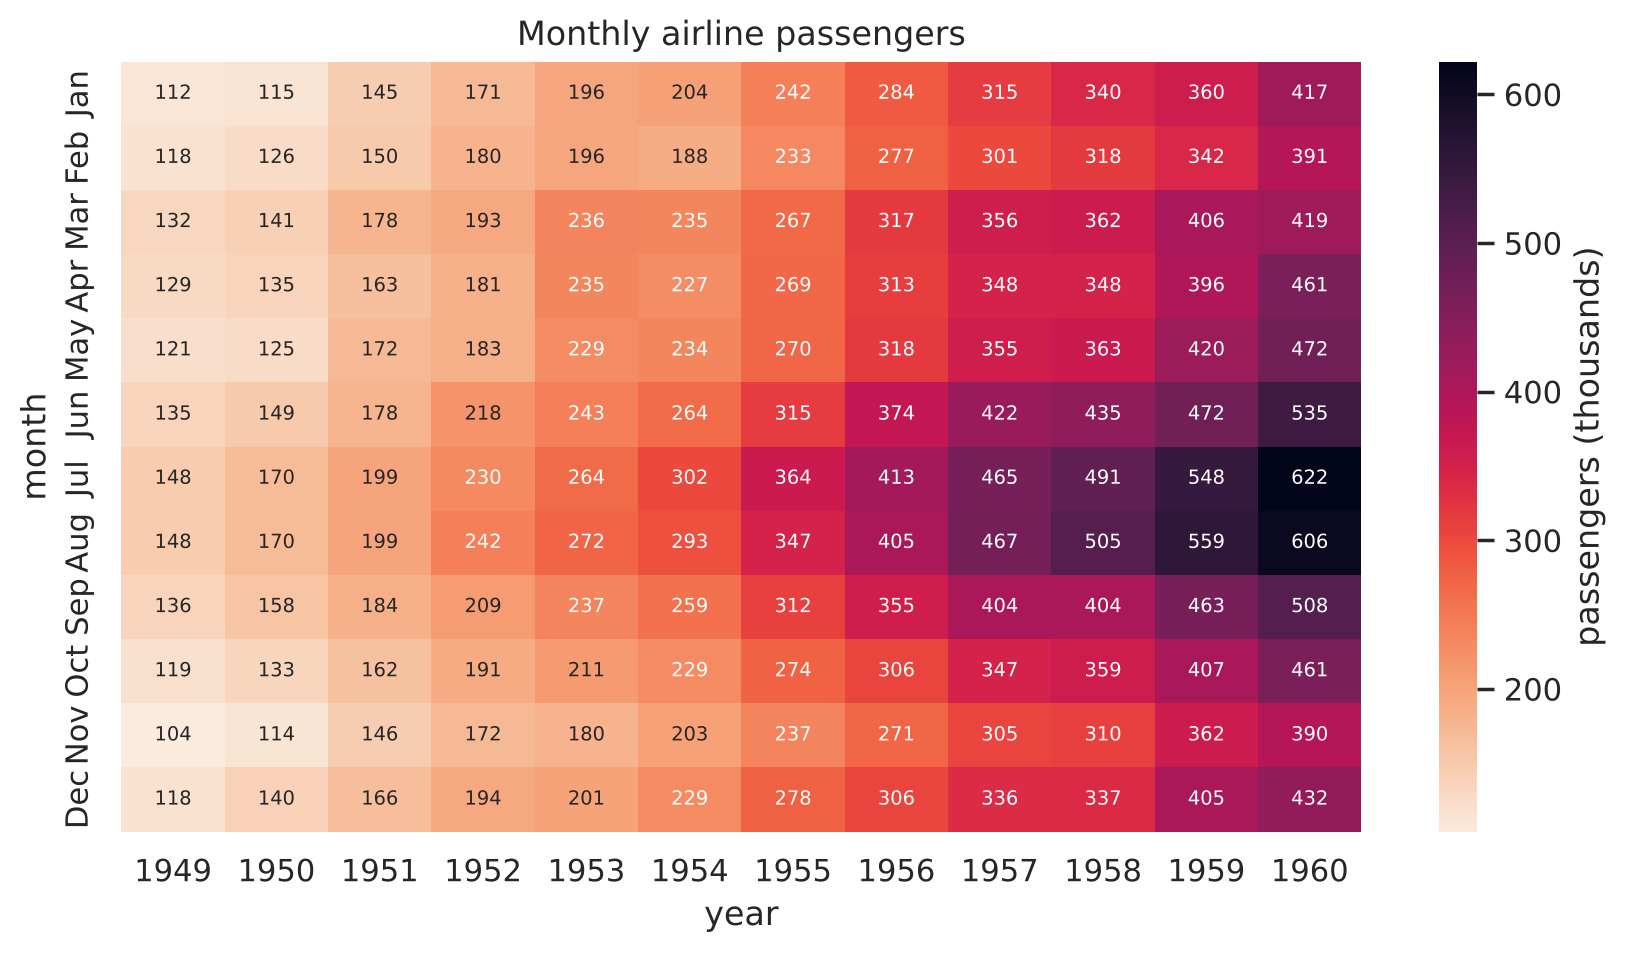

In [3]:
table = flights.pivot(index="month", columns="year", values="passengers")
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(table, cmap="rocket_r", annot=True, fmt="d", annot_kws={"size": 7},
            cbar_kws={"label": "passengers (thousands)"}, ax=ax)
ax.set_title("Monthly airline passengers")
plt.show()

**Reading it:** darker is more. Passengers rise from left to right (growth over the years) and the
darkest cells each year are July and August (summer peaks). Both patterns are visible at a glance, which
is hard from 144 numbers in a table.

## Correlation heatmap

A correlation matrix uses a **diverging** palette centred on zero, so positive and negative
correlations get different colours and zero is neutral.

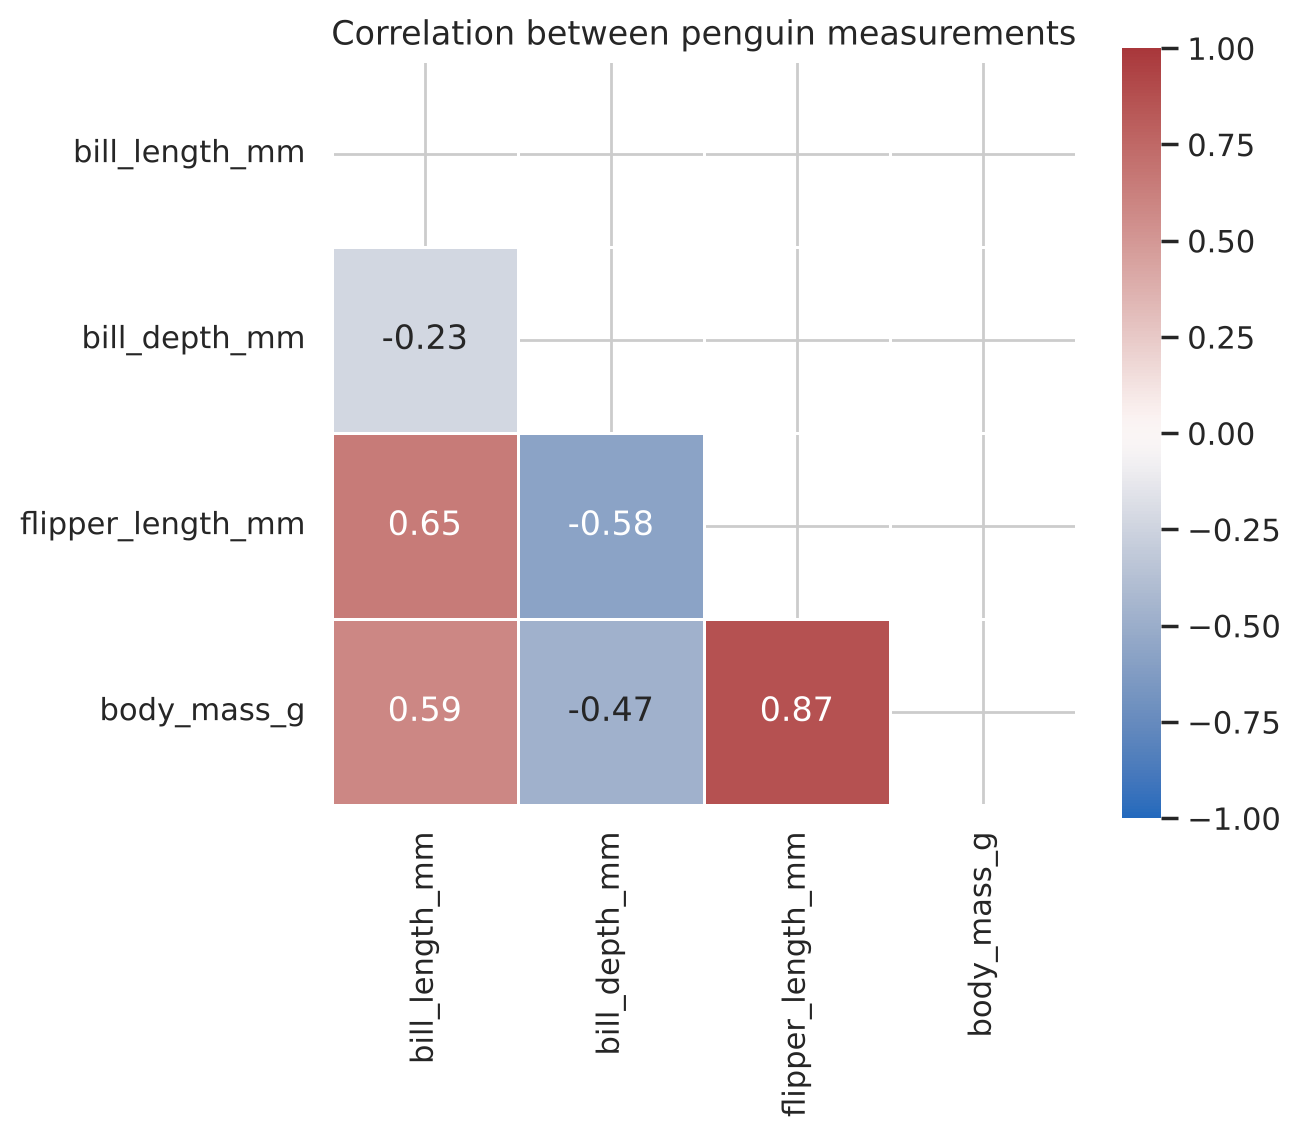

In [4]:
num = penguins.select_dtypes("number")
corr = num.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))      # hide the repeated upper triangle

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, mask=mask, cmap="vlag", vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation between penguin measurements")
plt.show()

Flipper length and body mass are strongly positively correlated (0.87); bill depth is negatively
correlated with the others across species, an effect of the species differences seen in notebook 04.

## Gene expression heatmap

Expression matrices are usually standardised per gene (z-scores), so that genes with different overall
levels can be compared on one colour scale. `clustermap` also reorders rows and columns so similar
ones sit together.

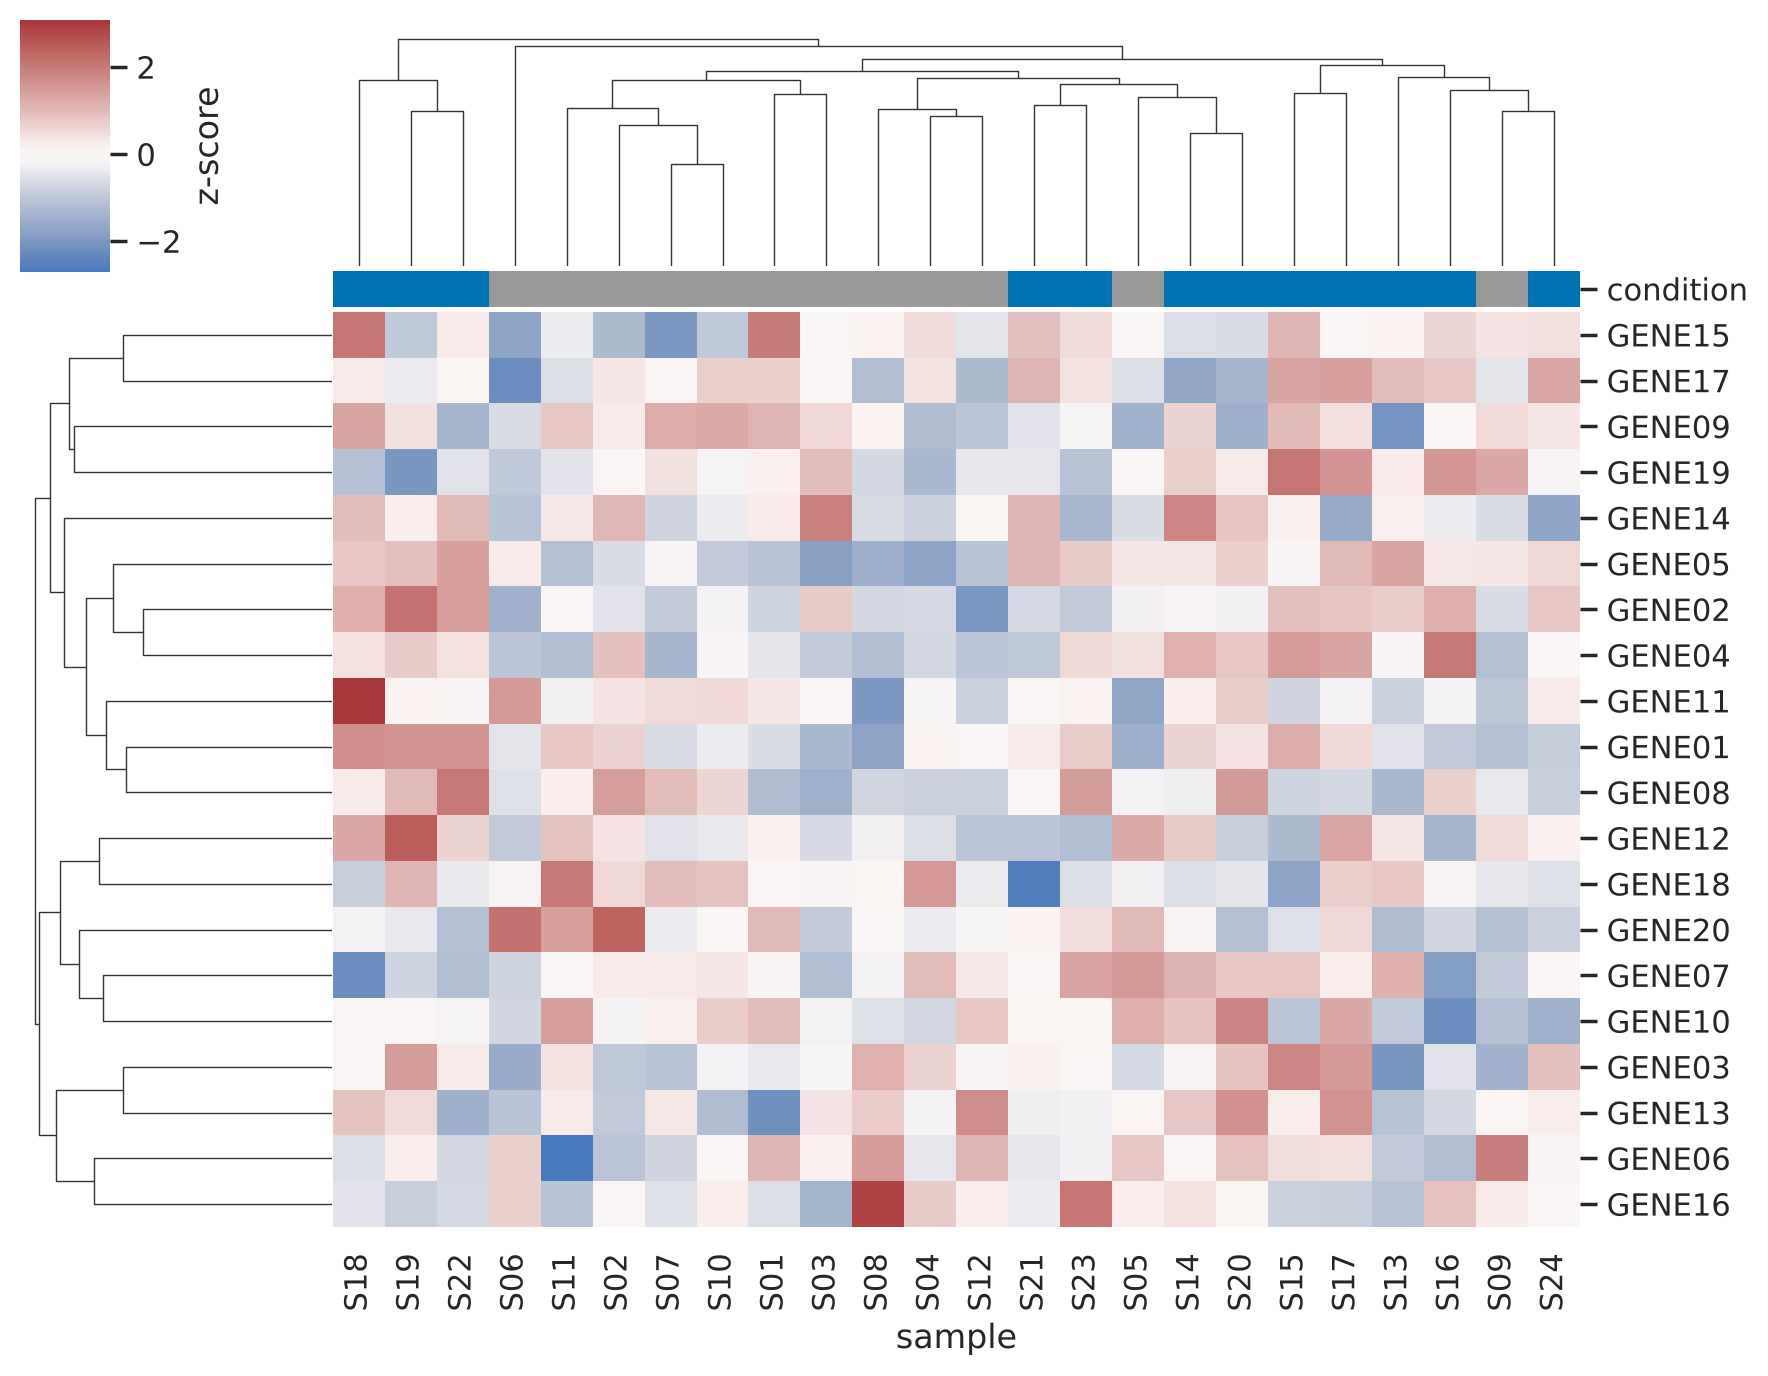

In [5]:
expr = pd.read_csv(RAW + "gene_expression.tsv", sep="\t", index_col="sample")
condition = expr.pop("condition")
z = (expr - expr.mean()) / expr.std()

colours = condition.map({"control": "#999999", "treated": "#0072B2"})
g = sns.clustermap(z.T, cmap="vlag", center=0, col_colors=colours, figsize=(9, 7),
                   cbar_kws={"label": "z-score"})
plt.show()

Each column is a sample (the top bar marks its condition), each row a gene. If treatment changes some
genes, those rows show colour that differs between treated and control samples. Here the treatment
effect is modest, so the clustering only partly separates the conditions: most control samples group
together, but some treated and control samples mix. That is common with real expression data, and a
reason not to over-read a heatmap: it is a picture for exploring, not a test.

## pairplot

Every pair of numeric variables as a scatter plot, with each variable's distribution on the diagonal.
A quick first look at a new dataset.

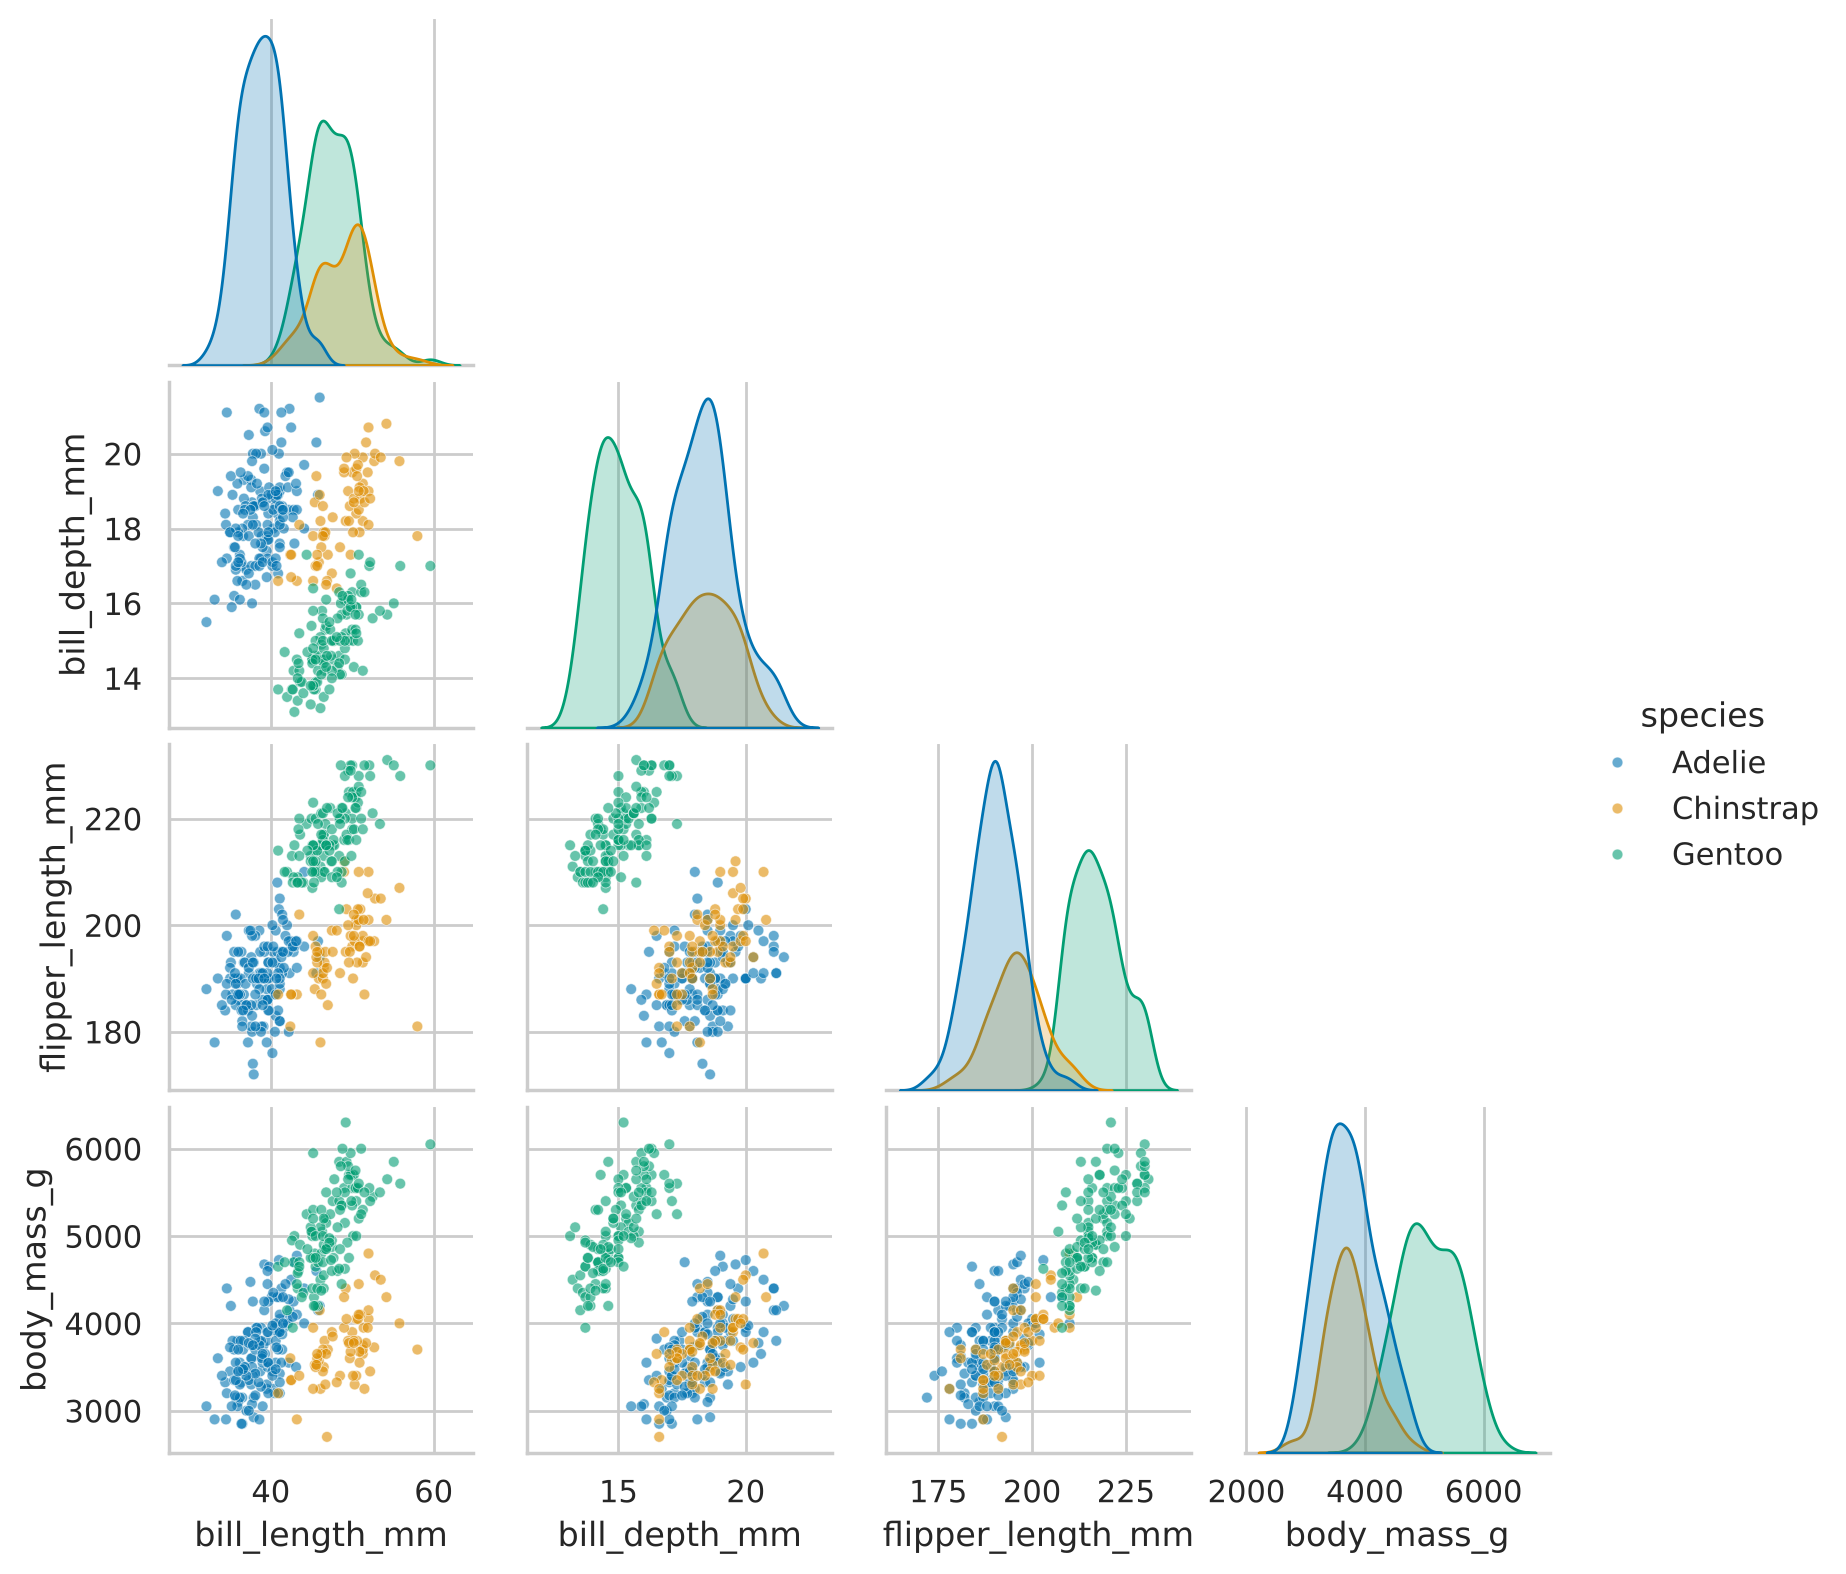

In [6]:
sns.pairplot(penguins, hue="species", palette="colorblind", corner=True, height=2,
             plot_kws={"alpha": 0.6, "s": 15})
plt.show()

`corner=True` drops the repeated upper half. Look for pairs where the species separate cleanly, and
for curved or unusual patterns worth a closer look.

## FacetGrid: custom small multiples

`FacetGrid` sets up panels by `row` and `col`, then `map` or `map_dataframe` draws any function in each.

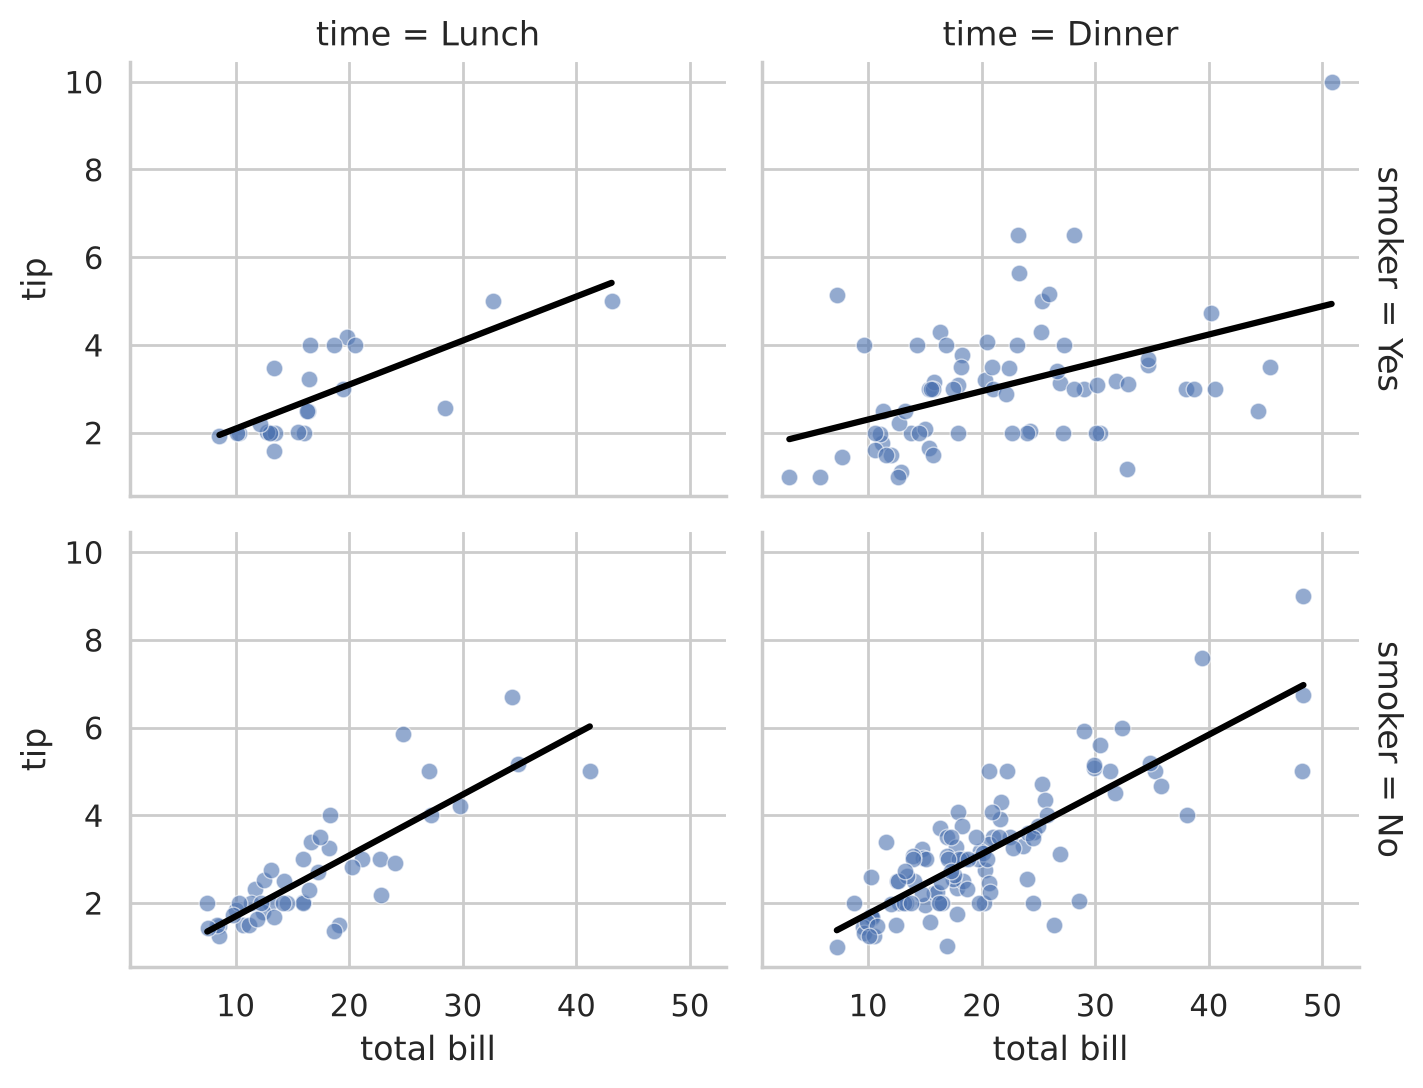

In [7]:
tips = sns.load_dataset("tips")
g = sns.FacetGrid(tips, col="time", row="smoker", height=2.8, aspect=1.3, margin_titles=True)
g.map_dataframe(sns.scatterplot, x="total_bill", y="tip", alpha=0.6)
g.map_dataframe(sns.regplot, x="total_bill", y="tip", scatter=False, color="black", ci=None)
g.set_axis_labels("total bill", "tip")
plt.show()

`col_wrap` wraps a long row of panels:

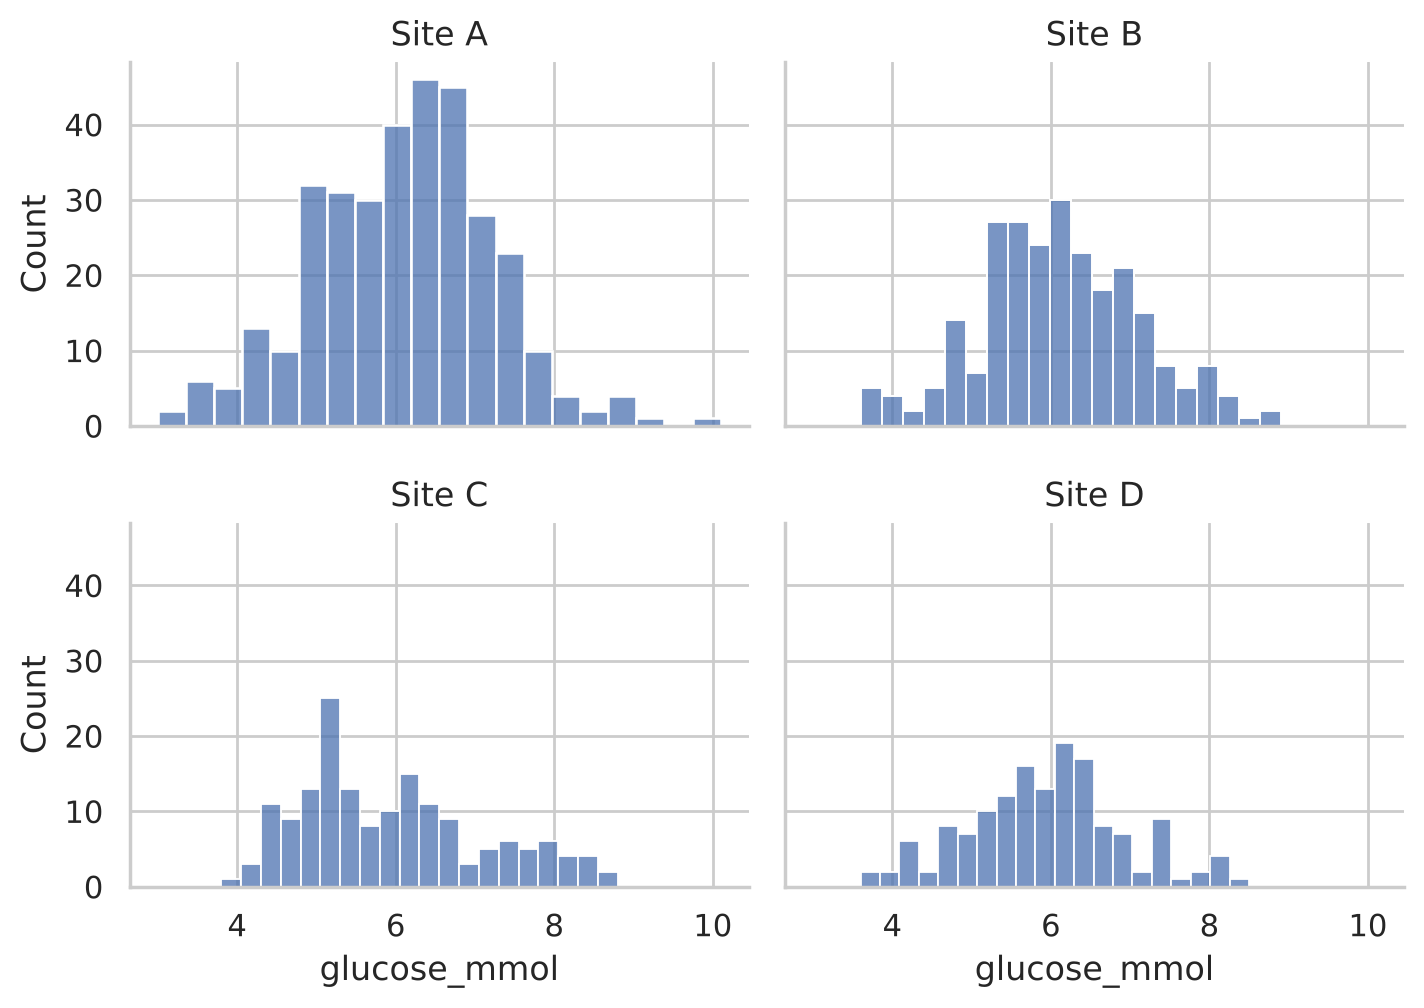

In [8]:
labs = pd.read_csv(RAW + "lab_results.csv")
patients = pd.read_csv(RAW + "patients.csv")
df = labs.merge(patients[["patient_id", "site"]], on="patient_id")
g = sns.FacetGrid(df, col="site", col_wrap=2, height=2.6, aspect=1.4, sharex=True, sharey=True)
g.map_dataframe(sns.histplot, x="glucose_mmol", bins=20)
g.set_titles("{col_name}")
plt.show()

## Publication-quality figures

A checklist:

1. **size for the destination**: a journal single column is about 3.5 inches (89 mm) wide, a double
   column about 7 inches (180 mm). Draw at the final size, so text is not shrunk
2. **readable text**: 7-9 pt at final size; `sns.set_theme(context="paper")` helps
3. **labels with units** on every axis; no internal variable names such as `glucose_mmol`
4. **colour-blind-safe palette**, plus markers or labels so nothing depends on colour alone
5. **consistent colours** for the same group across all figures
6. **say what error bars show** (SD, SE or CI) in the caption
7. **vector format** (PDF, SVG) or PNG/TIFF at 300 dpi or more
8. **panel letters** (A, B, C) for multi-panel figures

A template that puts these together:

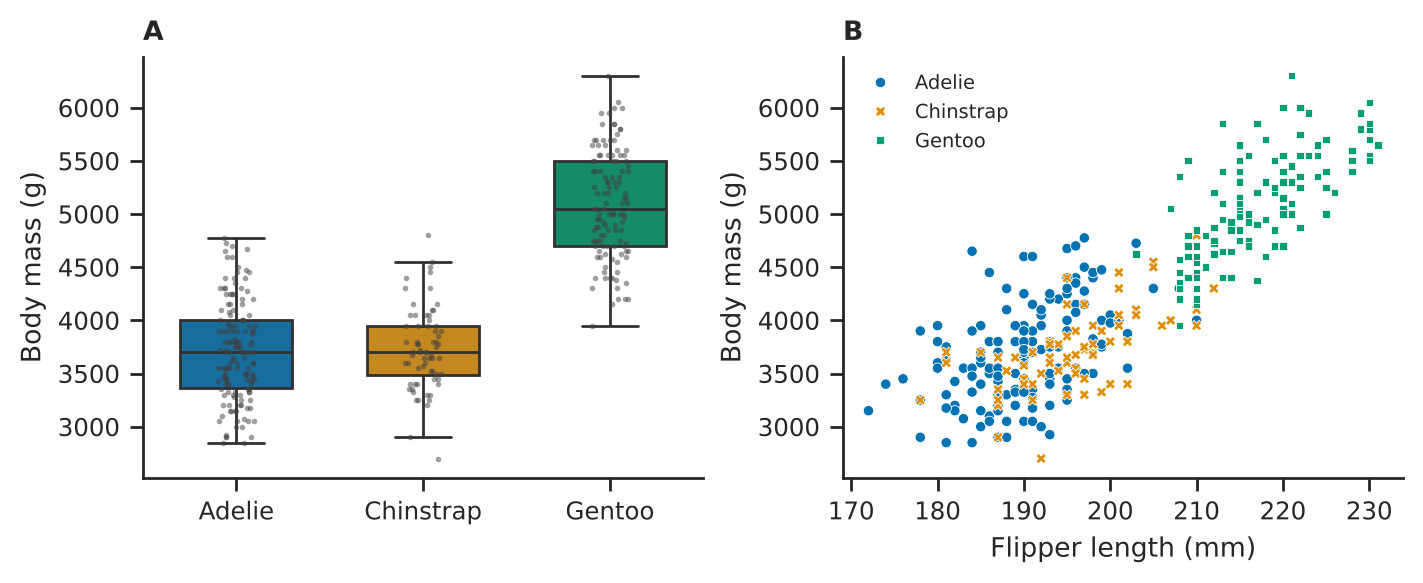

In [9]:
sns.set_theme(style="ticks", context="paper", font_scale=1.0)
palette = dict(zip(["Adelie", "Chinstrap", "Gentoo"], sns.color_palette("colorblind", 3)))

fig, axes = plt.subplots(1, 2, figsize=(7, 2.8), layout="constrained")

sns.boxplot(data=penguins, x="species", y="body_mass_g", hue="species", palette=palette,
            showfliers=False, width=0.6, ax=axes[0])
sns.stripplot(data=penguins, x="species", y="body_mass_g", color="0.25", size=2, alpha=0.5, ax=axes[0])
axes[0].set(xlabel="", ylabel="Body mass (g)")
axes[0].set_title("A", loc="left", fontweight="bold")

sns.scatterplot(data=penguins, x="flipper_length_mm", y="body_mass_g", hue="species", style="species",
                palette=palette, s=14, ax=axes[1])
axes[1].set(xlabel="Flipper length (mm)", ylabel="Body mass (g)")
axes[1].set_title("B", loc="left", fontweight="bold")
axes[1].legend(title=None, frameon=False, fontsize=7)

sns.despine(fig)
fig.savefig("figure1.pdf")
fig.savefig("figure1.png", dpi=300)
plt.show()

Caption: *Figure 1. (A) Body mass by species; boxes show the median and interquartile range, points
show individual birds. (B) Body mass against flipper length.*

In [10]:
import os
for f in ["figure1.pdf", "figure1.png"]:
    print(f, os.path.getsize(f) // 1024, "KB")
    os.remove(f)
sns.set_theme()

figure1.pdf 44 KB
figure1.png 178 KB


## Practise

Exercises for this folder are in `exercises/Seaborn_Exercises.ipynb`.

## Further reading

- [Seaborn tutorial](https://seaborn.pydata.org/tutorial.html)
- [heatmap](https://seaborn.pydata.org/generated/seaborn.heatmap.html) and [clustermap](https://seaborn.pydata.org/generated/seaborn.clustermap.html)
- [Building structured multi-plot grids](https://seaborn.pydata.org/tutorial/axis_grids.html)
- [Ten simple rules for better figures (Rougier et al., 2014)](https://doi.org/10.1371/journal.pcbi.1003833)